In [1]:
import os
import ast
import re
import time
import requests

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader

In [2]:
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

BASE_DIR = "poke_sprite"

METADATA_PATH = os.path.join(
    BASE_DIR, "dataset_split.csv"
)

STATS_CACHE_PATH = os.path.join(
    BASE_DIR, "pokemon_stats.csv"
)

ENRICHED_METADATA_PATH = os.path.join(
    BASE_DIR, "dataset_with_stats.csv"
)

IMAGE_SIZE = 64
BATCH_SIZE = 32

print("Dispositivo:", DEVICE)
print("Diretório:", os.path.abspath(BASE_DIR))

Dispositivo: cuda
Diretório: c:\Mestrado\Projeto_poke_sprite\poke_sprite


# Dados

In [63]:
# Diretório do projeto
PROJECT_DIR = r"C:\Mestrado\Projeto_poke_sprite"

# Diretório dos dados
BASE_DIR = os.path.join(PROJECT_DIR, "poke_sprite")

# Arquivo original com os metadados e a divisão dos dados
SOURCE_CSV = os.path.join(
    BASE_DIR,
    "dataset_split.csv"
)

# Diretórios de imagens e máscaras
IMAGE_DIR = os.path.join(BASE_DIR, "processed_masked")
MASK_DIR = os.path.join(BASE_DIR, "masks")

# Novo cache, independente dos arquivos anteriores
API_CACHE_PATH = os.path.join(
    BASE_DIR,
    "pokemon_api_data_verified.csv"
)

# Dataset final
FINAL_CSV = os.path.join(
    BASE_DIR,
    "dataset_with_conditions.csv"
)

# Verificar diretórios
assert os.path.exists(SOURCE_CSV), "dataset_split.csv não encontrado!"
assert os.path.isdir(IMAGE_DIR), "Pasta processed_masked não encontrada!"
assert os.path.isdir(MASK_DIR), "Pasta masks não encontrada!"

print("Diretórios encontrados!")
print("BASE_DIR:", BASE_DIR)

Diretórios encontrados!
BASE_DIR: C:\Mestrado\Projeto_poke_sprite\poke_sprite


In [64]:
df_base = pd.read_csv(SOURCE_CSV)

# Padronizar os IDs
df_base["id"] = pd.to_numeric(
    df_base["id"],
    errors="raise"
).astype(int)

# Padronizar nomes e divisão
df_base["pokemon_name"] = (
    df_base["pokemon_name"]
    .astype(str)
    .str.strip()
    .str.lower()
)

df_base["split"] = (
    df_base["split"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Conferir colunas necessárias
required_columns = {
    "id",
    "pokemon_name",
    "split",
    "raw_path"
}

missing_columns = required_columns - set(df_base.columns)

assert not missing_columns, (
    f"Colunas ausentes no dataset original: {missing_columns}"
)

# Verificações
assert df_base["id"].is_unique, "Existem IDs duplicados!"
assert df_base["pokemon_name"].notna().all()
assert df_base["raw_path"].notna().all()

print("Dimensão:", df_base.shape)
print("\nDistribuição dos conjuntos:")
print(df_base["split"].value_counts())

print("\nPrimeiros Pokémon:")
display(
    df_base[
        ["id", "pokemon_name", "split", "raw_path"]
    ].head(10)
)

Dimensão: (1025, 12)

Distribuição dos conjuntos:
split
train         905
validation     60
test           60
Name: count, dtype: int64

Primeiros Pokémon:


,id,pokemon_name,split,raw_path
0,1,bulbasaur,train,poke_sprite\raw\0001_bulbasaur.png
1,2,ivysaur,train,poke_sprite\raw\0002_ivysaur.png
2,3,venusaur,train,poke_sprite\raw\0003_venusaur.png
3,4,charmander,train,poke_sprite\raw\0004_charmander.png
4,5,charmeleon,train,poke_sprite\raw\0005_charmeleon.png
5,6,charizard,train,poke_sprite\raw\0006_charizard.png
6,7,squirtle,train,poke_sprite\raw\0007_squirtle.png
7,8,wartortle,train,poke_sprite\raw\0008_wartortle.png
8,9,blastoise,train,poke_sprite\raw\0009_blastoise.png
9,10,caterpie,train,poke_sprite\raw\0010_caterpie.png


In [65]:
expected_counts = {
    "train": 905,
    "validation": 60,
    "test": 60
}

actual_counts = df_base["split"].value_counts().to_dict()

assert actual_counts == expected_counts, (
    f"Distribuição diferente da esperada: {actual_counts}"
)

print("Divisão dos dados validada!")

Divisão dos dados validada!


In [66]:
POKEMON_TYPES = [
    "normal",
    "fire",
    "water",
    "electric",
    "grass",
    "ice",
    "fighting",
    "poison",
    "ground",
    "flying",
    "psychic",
    "bug",
    "rock",
    "ghost",
    "dragon",
    "dark",
    "steel",
    "fairy"
]

STAT_COLUMNS = [
    "hp",
    "attack",
    "defense",
    "special_attack",
    "special_defense",
    "speed"
]

# Correspondência entre os nomes usados pela API
# e os nomes das nossas colunas
API_STAT_NAMES = {
    "hp": "hp",
    "attack": "attack",
    "defense": "defense",
    "special-attack": "special_attack",
    "special-defense": "special_defense",
    "speed": "speed"
}

print("Quantidade de tipos:", len(POKEMON_TYPES))
print("Quantidade de status:", len(STAT_COLUMNS))

Quantidade de tipos: 18
Quantidade de status: 6


In [67]:
def fetch_pokemon_data(pokemon_id, session):

    url = f"https://pokeapi.co/api/v2/pokemon/{pokemon_id}/"

    response = None

    # Tentativas com tratamento de falhas temporárias
    for attempt in range(5):

        try:
            response = session.get(
                url,
                timeout=30
            )

            response.raise_for_status()
            break

        except requests.RequestException:

            if attempt == 4:
                raise

            time.sleep(2 ** attempt)

    data = response.json()

    # ID e nome retornados pela própria API
    api_id = int(data["id"])
    api_name = data["name"].lower()

    # Tipos ordenados pelo slot
    types = sorted(
        data["types"],
        key=lambda item: item["slot"]
    )

    types = [
        item["type"]["name"]
        for item in types
    ]

    # Status em um dicionário indexado pelo nome
    raw_stats = {
        item["stat"]["name"]: int(item["base_stat"])
        for item in data["stats"]
    }

    # Verificar se todos os seis status foram encontrados
    assert set(raw_stats.keys()) == set(API_STAT_NAMES.keys()), (
        f"Status inesperados para {api_name}: {raw_stats.keys()}"
    )

    record = {
        "id": api_id,
        "api_name": api_name,
        "types": "|".join(types)
    }

    for api_stat_name, column_name in API_STAT_NAMES.items():
        record[column_name] = raw_stats[api_stat_name]

    return record

In [68]:
def normalize_name(name):
    return str(name).strip().lower().replace(" ", "-")


def validate_api_cache(cache_df, source_df):

    required = {
        "id",
        "api_name",
        "types",
        *STAT_COLUMNS
    }

    if not required.issubset(cache_df.columns):
        return False

    if cache_df["id"].duplicated().any():
        return False

    source_ids = set(source_df["id"].astype(int))
    cache_ids = set(cache_df["id"].astype(int))

    if source_ids != cache_ids:
        return False

    expected_names = (
        source_df
        .set_index("id")["pokemon_name"]
        .map(normalize_name)
    )

    cached_names = (
        cache_df
        .set_index("id")["api_name"]
        .map(normalize_name)
    )

    for pokemon_id in source_ids:

        if expected_names.loc[pokemon_id] != cached_names.loc[pokemon_id]:
            return False

    return True

In [69]:
if os.path.exists(API_CACHE_PATH):

    cached_df = pd.read_csv(API_CACHE_PATH)

    if validate_api_cache(cached_df, df_base):

        print("Cache validado. Reutilizando os dados da PokeAPI.")

        api_df = cached_df.copy()

    else:

        print("Cache inválido. Consultando novamente a PokeAPI.")

        api_df = None

else:

    print("Cache ainda não existe. Consultando a PokeAPI.")

    api_df = None

Cache ainda não existe. Consultando a PokeAPI.


In [70]:
if api_df is None:

    session = requests.Session()

    records = []

    pokemon_ids = sorted(
        df_base["id"].unique().tolist()
    )

    for i, pokemon_id in enumerate(pokemon_ids, start=1):

        record = fetch_pokemon_data(
            pokemon_id,
            session
        )

        # Conferir se a API retornou o mesmo ID solicitado
        assert record["id"] == pokemon_id, (
            f"ID incorreto! Solicitado {pokemon_id}, "
            f"recebido {record['id']}"
        )

        # Conferir se o nome também corresponde
        source_name = df_base.loc[
            df_base["id"] == pokemon_id,
            "pokemon_name"
        ].iloc[0]

        assert normalize_name(record["api_name"]) == normalize_name(source_name), (
            f"Nome incompatível no ID {pokemon_id}: "
            f"dataset={source_name}, API={record['api_name']}"
        )

        records.append(record)

        if i % 50 == 0 or i == len(pokemon_ids):

            print(
                f"Consultados: {i}/{len(pokemon_ids)}"
            )

    api_df = pd.DataFrame(records)

    # Garantir um registro por ID
    assert api_df["id"].is_unique
    assert len(api_df) == len(df_base)

    # Salvar o cache novo
    api_df.to_csv(
        API_CACHE_PATH,
        index=False
    )

    print("\nConsulta finalizada!")
    print("Cache salvo em:", API_CACHE_PATH)

Consultados: 50/1025
Consultados: 100/1025
Consultados: 150/1025
Consultados: 200/1025
Consultados: 250/1025
Consultados: 300/1025
Consultados: 350/1025
Consultados: 400/1025
Consultados: 450/1025
Consultados: 500/1025
Consultados: 550/1025
Consultados: 600/1025
Consultados: 650/1025
Consultados: 700/1025
Consultados: 750/1025
Consultados: 800/1025
Consultados: 850/1025
Consultados: 900/1025
Consultados: 950/1025
Consultados: 1000/1025
Consultados: 1025/1025

Consulta finalizada!
Cache salvo em: C:\Mestrado\Projeto_poke_sprite\poke_sprite\pokemon_api_data_verified.csv


In [71]:
print("Dimensão da tabela:", api_df.shape)

print("\nColunas:")
print(api_df.columns.tolist())

print("\nPrimeiros registros:")
display(
    api_df[
        ["id", "api_name", "types"] + STAT_COLUMNS
    ].head(10)
)

Dimensão da tabela: (1025, 9)

Colunas:
['id', 'api_name', 'types', 'hp', 'attack', 'defense', 'special_attack', 'special_defense', 'speed']

Primeiros registros:


,id,api_name,types,hp,attack,defense,special_attack,special_defense,speed
0,1,bulbasaur,grass|poison,45,49,49,65,65,45
1,2,ivysaur,grass|poison,60,62,63,80,80,60
2,3,venusaur,grass|poison,80,82,83,100,100,80
3,4,charmander,fire,39,52,43,60,50,65
4,5,charmeleon,fire,58,64,58,80,65,80
5,6,charizard,fire|flying,78,84,78,109,85,100
6,7,squirtle,water,44,48,65,50,64,43
7,8,wartortle,water,59,63,80,65,80,58
8,9,blastoise,water,79,83,100,85,105,78
9,10,caterpie,bug,45,30,35,20,20,45


In [72]:
bulbasaur_api = api_df[
    api_df["id"] == 1
].iloc[0]

print("ID:", bulbasaur_api["id"])
print("Nome:", bulbasaur_api["api_name"])
print("Tipos:", bulbasaur_api["types"])

for stat in STAT_COLUMNS:
    print(f"{stat}: {bulbasaur_api[stat]}")

# Validação automática
assert bulbasaur_api["api_name"] == "bulbasaur"
assert bulbasaur_api["types"] == "grass|poison"

expected_bulbasaur_stats = {
    "hp": 45,
    "attack": 49,
    "defense": 49,
    "special_attack": 65,
    "special_defense": 65,
    "speed": 45
}

for stat, expected_value in expected_bulbasaur_stats.items():

    assert int(bulbasaur_api[stat]) == expected_value, (
        f"Valor incorreto para {stat}: "
        f"{bulbasaur_api[stat]}"
    )

print("\nBulbasaur validado corretamente!")

ID: 1
Nome: bulbasaur
Tipos: grass|poison
hp: 45
attack: 49
defense: 49
special_attack: 65
special_defense: 65
speed: 45

Bulbasaur validado corretamente!


In [73]:
known_pokemon = [
    "bulbasaur",
    "ivysaur",
    "venusaur",
    "charmander",
    "charmeleon",
    "charizard",
    "squirtle",
    "wartortle",
    "blastoise"
]

display(
    api_df[
        api_df["api_name"].isin(known_pokemon)
    ][
        ["id", "api_name", "types"] + STAT_COLUMNS
    ].sort_values("id")
)

,id,api_name,types,hp,attack,defense,special_attack,special_defense,speed
0,1,bulbasaur,grass|poison,45,49,49,65,65,45
1,2,ivysaur,grass|poison,60,62,63,80,80,60
2,3,venusaur,grass|poison,80,82,83,100,100,80
3,4,charmander,fire,39,52,43,60,50,65
4,5,charmeleon,fire,58,64,58,80,65,80
5,6,charizard,fire|flying,78,84,78,109,85,100
6,7,squirtle,water,44,48,65,50,64,43
7,8,wartortle,water,59,63,80,65,80,58
8,9,blastoise,water,79,83,100,85,105,78


In [74]:
df = df_base.merge(
    api_df,
    on="id",
    how="left",
    validate="one_to_one",
    indicator=True
)

# Verificar se todos os registros foram associados
print(df["_merge"].value_counts())

assert (df["_merge"] == "both").all(), (
    "Existem Pokémon sem correspondência na PokeAPI!"
)

# Conferir nomes
df["pokemon_name"] = df["pokemon_name"].map(normalize_name)

assert (
    df["pokemon_name"] == df["api_name"]
).all(), "Existem nomes incompatíveis após a associação!"

# Remover a coluna auxiliar
df.drop(columns=["_merge"], inplace=True)

print("Associação pelo ID concluída!")
print("Total de registros:", len(df))

_merge
both          1025
left_only        0
right_only       0
Name: count, dtype: int64
Associação pelo ID concluída!
Total de registros: 1025


C:\Users\Administrador\AppData\Local\Temp\ipykernel_27892\981999662.py:24: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["_merge"], inplace=True)


In [76]:
# Verificar as colunas relacionadas aos tipos
print([
    column
    for column in df.columns
    if "types" in column
])

# Preservar os tipos originais e utilizar os da API
if "types_y" in df.columns:

    df = df.rename(columns={
        "types_x": "types_source",
        "types_y": "types"
    })

elif "types" not in df.columns:

    raise KeyError(
        "Não foi encontrada uma coluna válida de tipos."
    )

print("\nColunas corrigidas!")

print([
    column
    for column in df.columns
    if "types" in column
])

['types_x', 'num_types', 'types_y']

Colunas corrigidas!
['types_source', 'num_types', 'types']


In [77]:
display(
    df[
        ["id", "pokemon_name", "api_name", "types"]
        + STAT_COLUMNS
    ].head(10)
)

,id,pokemon_name,api_name,types,hp,attack,defense,special_attack,special_defense,speed
0,1,bulbasaur,bulbasaur,grass|poison,45,49,49,65,65,45
1,2,ivysaur,ivysaur,grass|poison,60,62,63,80,80,60
2,3,venusaur,venusaur,grass|poison,80,82,83,100,100,80
3,4,charmander,charmander,fire,39,52,43,60,50,65
4,5,charmeleon,charmeleon,fire,58,64,58,80,65,80
5,6,charizard,charizard,fire|flying,78,84,78,109,85,100
6,7,squirtle,squirtle,water,44,48,65,50,64,43
7,8,wartortle,wartortle,water,59,63,80,65,80,58
8,9,blastoise,blastoise,water,79,83,100,85,105,78
9,10,caterpie,caterpie,bug,45,30,35,20,20,45


In [78]:
NUM_TYPES = len(POKEMON_TYPES)
NUM_STATS = len(STAT_COLUMNS)

TYPE_FEATURE_COLUMNS = [
    f"type_{pokemon_type}"
    for pokemon_type in POKEMON_TYPES
]

type_to_index = {
    pokemon_type: index
    for index, pokemon_type in enumerate(POKEMON_TYPES)
}


def encode_types(types_string):

    types = str(types_string).split("|")

    vector = np.zeros(
        NUM_TYPES,
        dtype=np.float32
    )

    for pokemon_type in types:

        pokemon_type = pokemon_type.strip()

        assert pokemon_type in type_to_index, (
            f"Tipo desconhecido: {pokemon_type}"
        )

        vector[type_to_index[pokemon_type]] = 1.0

    return vector

In [79]:
type_matrix = np.stack(
    df["types"].apply(encode_types).values
)

assert type_matrix.shape == (
    len(df),
    NUM_TYPES
)

df[TYPE_FEATURE_COLUMNS] = type_matrix

print("Shape dos tipos:", type_matrix.shape)

display(
    df[
        ["pokemon_name", "types"] + TYPE_FEATURE_COLUMNS
    ].head()
)

Shape dos tipos: (1025, 18)


,pokemon_name,types,type_normal,type_fire,type_water,type_electric,type_grass,type_ice,type_fighting,type_poison,type_ground,type_flying,type_psychic,type_bug,type_rock,type_ghost,type_dragon,type_dark,type_steel,type_fairy
0,bulbasaur,grass|poison,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,ivysaur,grass|poison,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,venusaur,grass|poison,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,charmander,fire,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,charmeleon,fire,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [80]:
NORMALIZATION_FACTOR = 255.0

NORMALIZED_STAT_COLUMNS = [
    f"{stat}_norm"
    for stat in STAT_COLUMNS
]

# Conferir os limites dos status originais
print("Mínimo dos status:")
print(df[STAT_COLUMNS].min())

print("\nMáximo dos status:")
print(df[STAT_COLUMNS].max())

assert (df[STAT_COLUMNS] >= 0).all().all()
assert (df[STAT_COLUMNS] <= NORMALIZATION_FACTOR).all().all()

# Normalização
for stat, normalized_stat in zip(
    STAT_COLUMNS,
    NORMALIZED_STAT_COLUMNS
):

    df[normalized_stat] = (
        df[stat].astype(np.float32)
        / NORMALIZATION_FACTOR
    )

print("Status normalizados!")

Mínimo dos status:
hp                  1
attack              5
defense             5
special_attack     10
special_defense    20
speed               5
dtype: int64

Máximo dos status:
hp                 255
attack             181
defense            230
special_attack     173
special_defense    230
speed              200
dtype: int64
Status normalizados!


In [81]:
CONDITION_COLUMNS = (
    TYPE_FEATURE_COLUMNS
    + NORMALIZED_STAT_COLUMNS
)

CONDITION_DIM = len(CONDITION_COLUMNS)

assert CONDITION_DIM == 24

# Conferir valores
assert df[TYPE_FEATURE_COLUMNS].isin([0.0, 1.0]).all().all()

assert (
    df[NORMALIZED_STAT_COLUMNS].to_numpy() >= 0
).all()

assert (
    df[NORMALIZED_STAT_COLUMNS].to_numpy() <= 1
).all()

print("Dimensão condicional:", CONDITION_DIM)

display(
    df[
        ["id", "pokemon_name", "types"]
        + NORMALIZED_STAT_COLUMNS
    ].head(10)
)

Dimensão condicional: 24


,id,pokemon_name,types,hp_norm,attack_norm,defense_norm,special_attack_norm,special_defense_norm,speed_norm
0,1,bulbasaur,grass|poison,0.176471,0.192157,0.192157,0.254902,0.254902,0.176471
1,2,ivysaur,grass|poison,0.235294,0.243137,0.247059,0.313726,0.313726,0.235294
2,3,venusaur,grass|poison,0.313726,0.321569,0.325490,0.392157,0.392157,0.313726
3,4,charmander,fire,0.152941,0.203922,0.168627,0.235294,0.196078,0.254902
4,5,charmeleon,fire,0.227451,0.250980,0.227451,0.313726,0.254902,0.313726
5,6,charizard,fire|flying,0.305882,0.329412,0.305882,0.427451,0.333333,0.392157
6,7,squirtle,water,0.172549,0.188235,0.254902,0.196078,0.250980,0.168627
7,8,wartortle,water,0.231373,0.247059,0.313726,0.254902,0.313726,0.227451
8,9,blastoise,water,0.309804,0.325490,0.392157,0.333333,0.411765,0.305882
9,10,caterpie,bug,0.176471,0.117647,0.137255,0.078431,0.078431,0.176471


In [82]:
def inspect_pokemon(pokemon_name):

    row = df[
        df["pokemon_name"] == pokemon_name.lower()
    ]

    assert len(row) == 1, (
        f"Esperado exatamente um registro para {pokemon_name}"
    )

    row = row.iloc[0]

    active_types = [
        pokemon_type
        for pokemon_type in POKEMON_TYPES
        if row[f"type_{pokemon_type}"] == 1
    ]

    print("=" * 50)
    print("Pokémon:", row["pokemon_name"])
    print("ID:", row["id"])
    print("Tipos:", active_types)

    print("\nStatus originais:")

    for stat in STAT_COLUMNS:
        print(f"{stat}: {int(row[stat])}")

    print("\nStatus normalizados:")

    for stat in NORMALIZED_STAT_COLUMNS:
        print(f"{stat}: {row[stat]:.4f}")

    print("=" * 50)

In [83]:
inspect_pokemon("bulbasaur")
inspect_pokemon("ivysaur")
inspect_pokemon("venusaur")
inspect_pokemon("charmander")
inspect_pokemon("charmeleon")

Pokémon: bulbasaur
ID: 1
Tipos: ['grass', 'poison']

Status originais:
hp: 45
attack: 49
defense: 49
special_attack: 65
special_defense: 65
speed: 45

Status normalizados:
hp_norm: 0.1765
attack_norm: 0.1922
defense_norm: 0.1922
special_attack_norm: 0.2549
special_defense_norm: 0.2549
speed_norm: 0.1765
Pokémon: ivysaur
ID: 2
Tipos: ['grass', 'poison']

Status originais:
hp: 60
attack: 62
defense: 63
special_attack: 80
special_defense: 80
speed: 60

Status normalizados:
hp_norm: 0.2353
attack_norm: 0.2431
defense_norm: 0.2471
special_attack_norm: 0.3137
special_defense_norm: 0.3137
speed_norm: 0.2353
Pokémon: venusaur
ID: 3
Tipos: ['grass', 'poison']

Status originais:
hp: 80
attack: 82
defense: 83
special_attack: 100
special_defense: 100
speed: 80

Status normalizados:
hp_norm: 0.3137
attack_norm: 0.3216
defense_norm: 0.3255
special_attack_norm: 0.3922
special_defense_norm: 0.3922
speed_norm: 0.3137
Pokémon: charmander
ID: 4
Tipos: ['fire']

Status originais:
hp: 39
attack: 52
defense

In [84]:
def get_filename(path):

    # Funciona tanto com caminhos Windows quanto Linux
    return str(path).replace("\\", "/").split("/")[-1]


df["filename"] = df["raw_path"].apply(get_filename)

df["image_path"] = df["filename"].apply(
    lambda name: os.path.join(
        IMAGE_DIR,
        name
    )
)

df["mask_path"] = df["filename"].apply(
    lambda name: os.path.join(
        MASK_DIR,
        name
    )
)

In [85]:
missing_images = df[
    ~df["image_path"].apply(os.path.isfile)
]

missing_masks = df[
    ~df["mask_path"].apply(os.path.isfile)
]

print("Imagens ausentes:", len(missing_images))
print("Máscaras ausentes:", len(missing_masks))

assert missing_images.empty, (
    "Existem imagens processadas ausentes!"
)

assert missing_masks.empty, (
    "Existem máscaras ausentes!"
)

print("Todos os caminhos foram validados!")

Imagens ausentes: 0
Máscaras ausentes: 0
Todos os caminhos foram validados!


In [86]:
for i in range(min(5, len(df))):

    row = df.iloc[i]

    image = Image.open(
        row["image_path"]
    ).convert("L")

    mask = Image.open(
        row["mask_path"]
    ).convert("L")

    print(
        row["pokemon_name"],
        "| Imagem:", image.size,
        "| Máscara:", mask.size
    )

    assert image.size == (64, 64)
    assert mask.size == (64, 64)

print("Dimensões verificadas!")

bulbasaur | Imagem: (64, 64) | Máscara: (64, 64)
ivysaur | Imagem: (64, 64) | Máscara: (64, 64)
venusaur | Imagem: (64, 64) | Máscara: (64, 64)
charmander | Imagem: (64, 64) | Máscara: (64, 64)
charmeleon | Imagem: (64, 64) | Máscara: (64, 64)
Dimensões verificadas!


In [87]:
df.to_csv(
    FINAL_CSV,
    index=False
)

print("Dataset final salvo!")
print(FINAL_CSV)

print("\nDimensão:", df.shape)
print("\nDimensão condicional:", CONDITION_DIM)

display(
    df[
        [
            "id",
            "pokemon_name",
            "types"
        ] + CONDITION_COLUMNS
    ].head()
)

Dataset final salvo!
C:\Mestrado\Projeto_poke_sprite\poke_sprite\dataset_with_conditions.csv

Dimensão: (1025, 47)

Dimensão condicional: 24


,id,pokemon_name,types,type_normal,type_fire,type_water,type_electric,type_grass,type_ice,type_fighting,...,type_dragon,type_dark,type_steel,type_fairy,hp_norm,attack_norm,defense_norm,special_attack_norm,special_defense_norm,speed_norm
0,1,bulbasaur,grass|poison,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.176471,0.192157,0.192157,0.254902,0.254902,0.176471
1,2,ivysaur,grass|poison,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.235294,0.243137,0.247059,0.313726,0.313726,0.235294
2,3,venusaur,grass|poison,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.313726,0.321569,0.325490,0.392157,0.392157,0.313726
3,4,charmander,fire,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.152941,0.203922,0.168627,0.235294,0.196078,0.254902
4,5,charmeleon,fire,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.227451,0.250980,0.227451,0.313726,0.254902,0.313726


In [88]:
df = pd.read_csv(FINAL_CSV)

assert len(df) == 1025

assert set(CONDITION_COLUMNS).issubset(df.columns)

assert df["id"].is_unique

assert df["image_path"].apply(os.path.isfile).all()
assert df["mask_path"].apply(os.path.isfile).all()

print("CSV final carregado e validado!")

CSV final carregado e validado!


In [89]:
class PokemonDataset(Dataset):

    def __init__(self, dataframe):

        self.df = dataframe.reset_index(
            drop=True
        ).copy()

        # Caminhos
        self.image_paths = self.df[
            "image_path"
        ].tolist()

        self.mask_paths = self.df[
            "mask_path"
        ].tolist()

        # Condições: matriz N x 24
        self.conditions = self.df[
            CONDITION_COLUMNS
        ].to_numpy(
            dtype=np.float32
        )

        assert self.conditions.shape == (
            len(self.df),
            CONDITION_DIM
        )

    def __len__(self):

        return len(self.df)

    def __getitem__(self, index):

        # Carregar imagem grayscale
        image = Image.open(
            self.image_paths[index]
        ).convert("L")

        image = np.asarray(
            image,
            dtype=np.float32
        ) / 255.0

        # Carregar máscara
        mask = Image.open(
            self.mask_paths[index]
        ).convert("L")

        mask = np.asarray(
            mask,
            dtype=np.uint8
        )

        # Converter para máscara binária 0/1
        mask = (mask > 127).astype(
            np.float32
        )

        assert image.shape == (64, 64)
        assert mask.shape == (64, 64)

        # Garantir background zerado
        image = image * mask

        # Tensores
        image = torch.from_numpy(
            image.copy()
        ).unsqueeze(0)

        mask = torch.from_numpy(
            mask.copy()
        ).unsqueeze(0)

        condition = torch.from_numpy(
            self.conditions[index].copy()
        )

        return image, mask, condition

In [90]:
df["split"] = (
    df["split"]
    .astype(str)
    .str.strip()
    .str.lower()
)

train_df = df[
    df["split"] == "train"
].copy()

val_df = df[
    df["split"] == "validation"
].copy()

test_df = df[
    df["split"] == "test"
].copy()

print("Treino:", len(train_df))
print("Validação:", len(val_df))
print("Teste:", len(test_df))

Treino: 905
Validação: 60
Teste: 60


In [91]:
train_dataset = PokemonDataset(train_df)
val_dataset = PokemonDataset(val_df)
test_dataset = PokemonDataset(test_df)

print("Datasets criados!")

Datasets criados!


In [92]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("DataLoaders criados!")

DataLoaders criados!


In [93]:
images, masks, conditions = next(
    iter(train_loader)
)

print("Images:")
print("Shape:", images.shape)
print("Dtype:", images.dtype)
print("Range:", images.min().item(), images.max().item())

print("\nMasks:")
print("Shape:", masks.shape)
print("Dtype:", masks.dtype)
print("Valores:", torch.unique(masks))

print("\nConditions:")
print("Shape:", conditions.shape)
print("Dtype:", conditions.dtype)
print("Range:", conditions.min().item(), conditions.max().item())

Images:
Shape: torch.Size([32, 1, 64, 64])
Dtype: torch.float32
Range: 0.0 1.0

Masks:
Shape: torch.Size([32, 1, 64, 64])
Dtype: torch.float32
Valores: tensor([0., 1.])

Conditions:
Shape: torch.Size([32, 24])
Dtype: torch.float32
Range: 0.0 1.0


In [94]:
def inspect_dataset_samples(dataset, num_samples=8):

    for i in range(min(num_samples, len(dataset))):

        image, mask, condition = dataset[i]

        row = dataset.df.iloc[i]

        active_types = [
            POKEMON_TYPES[j]
            for j in range(NUM_TYPES)
            if condition[j].item() == 1.0
        ]

        stats = (
            condition[NUM_TYPES:].numpy()
            * NORMALIZATION_FACTOR
        )

        print("=" * 55)
        print("Pokémon:", row["pokemon_name"])
        print("ID:", row["id"])
        print("Tipos:", active_types)

        print("Status recuperados:")

        for stat, value in zip(STAT_COLUMNS, stats):
            print(f"{stat}: {value:.0f}")

        print(
            "Imagem:", tuple(image.shape),
            "| Máscara:", tuple(mask.shape),
            "| Condição:", tuple(condition.shape)
        )


inspect_dataset_samples(train_dataset, 8)

Pokémon: bulbasaur
ID: 1
Tipos: ['grass', 'poison']
Status recuperados:
hp: 45
attack: 49
defense: 49
special_attack: 65
special_defense: 65
speed: 45
Imagem: (1, 64, 64) | Máscara: (1, 64, 64) | Condição: (24,)
Pokémon: ivysaur
ID: 2
Tipos: ['grass', 'poison']
Status recuperados:
hp: 60
attack: 62
defense: 63
special_attack: 80
special_defense: 80
speed: 60
Imagem: (1, 64, 64) | Máscara: (1, 64, 64) | Condição: (24,)
Pokémon: venusaur
ID: 3
Tipos: ['grass', 'poison']
Status recuperados:
hp: 80
attack: 82
defense: 83
special_attack: 100
special_defense: 100
speed: 80
Imagem: (1, 64, 64) | Máscara: (1, 64, 64) | Condição: (24,)
Pokémon: charmander
ID: 4
Tipos: ['fire']
Status recuperados:
hp: 39
attack: 52
defense: 43
special_attack: 60
special_defense: 50
speed: 65
Imagem: (1, 64, 64) | Máscara: (1, 64, 64) | Condição: (24,)
Pokémon: charmeleon
ID: 5
Tipos: ['fire']
Status recuperados:
hp: 58
attack: 64
defense: 58
special_attack: 80
special_defense: 65
speed: 80
Imagem: (1, 64, 64) | 

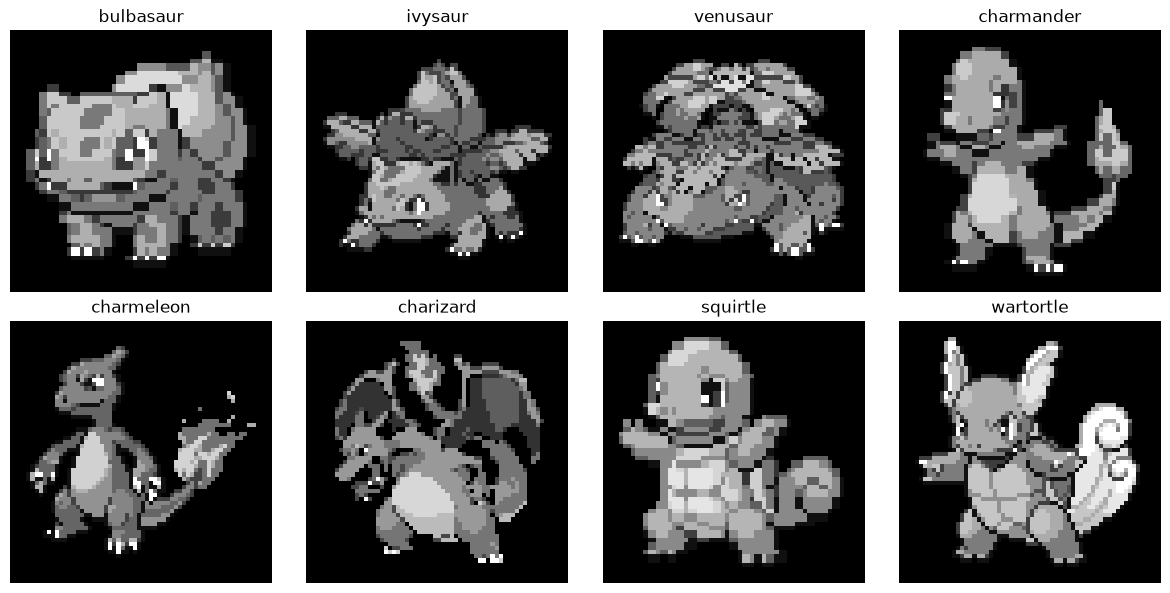

In [95]:
fig, axes = plt.subplots(
    2,
    4,
    figsize=(12, 6)
)

for i, ax in enumerate(axes.flat):

    image, mask, condition = train_dataset[i]

    row = train_dataset.df.iloc[i]

    ax.imshow(
        image.squeeze(0).numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.set_title(row["pokemon_name"])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [96]:
# Verificar quantidade de amostras
assert len(train_dataset) == 905
assert len(val_dataset) == 60
assert len(test_dataset) == 60

# Verificar dimensões das condições
assert train_dataset.conditions.shape == (905, 24)
assert val_dataset.conditions.shape == (60, 24)
assert test_dataset.conditions.shape == (60, 24)

# Verificar valores das condições
for dataset in [train_dataset, val_dataset, test_dataset]:

    assert np.isfinite(dataset.conditions).all()

    # Primeiras 18 posições: Multi-Hot
    assert np.isin(
        dataset.conditions[:, :18],
        [0.0, 1.0]
    ).all()

    # Últimas 6 posições: status normalizados
    assert (
        dataset.conditions[:, 18:] >= 0
    ).all()

    assert (
        dataset.conditions[:, 18:] <= 1
    ).all()

print("Todas as verificações foram aprovadas!")

Todas as verificações foram aprovadas!


In [97]:
df.to_csv(
    FINAL_CSV,
    index=False
)

print("Dataset final atualizado!")
print(FINAL_CSV)

Dataset final atualizado!
C:\Mestrado\Projeto_poke_sprite\poke_sprite\dataset_with_conditions.csv


# Modelo

In [98]:
# Dimensões
IMAGE_CHANNELS = 1
IMAGE_SIZE = 64

NUM_TYPES = 18
NUM_STATS = 6

CONDITION_DIM = NUM_TYPES + NUM_STATS
LATENT_DIM = 64

# Dispositivo
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Dispositivo:", DEVICE)
print("Dimensão da imagem:", IMAGE_SIZE)
print("Dimensão condicional:", CONDITION_DIM)
print("Dimensão latente:", LATENT_DIM)

Dispositivo: cuda
Dimensão da imagem: 64
Dimensão condicional: 24
Dimensão latente: 64


In [99]:
import torch.nn as nn
import torch.nn.functional as F


class Encoder(nn.Module):

    def __init__(
        self,
        condition_dim=24,
        latent_dim=64
    ):

        super().__init__()

        self.conv = nn.Sequential(

            # 64x64 -> 32x32
            nn.Conv2d(
                1 + condition_dim,
                32,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(32),
            nn.LeakyReLU(0.2, inplace=True),

            # 32x32 -> 16x16
            nn.Conv2d(
                32,
                64,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),

            # 16x16 -> 8x8
            nn.Conv2d(
                64,
                128,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            # 8x8 -> 4x4
            nn.Conv2d(
                128,
                128,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True)
        )

        self.fc = nn.Sequential(
            nn.Linear(128 * 4 * 4, 512),
            nn.LeakyReLU(0.2, inplace=True)
        )

        # Parâmetros da distribuição latente
        self.fc_mu = nn.Linear(512, latent_dim)
        self.fc_logvar = nn.Linear(512, latent_dim)

    def forward(self, x, c):

        batch_size = x.size(0)
        height = x.size(2)
        width = x.size(3)

        # Transformar condição em mapas espaciais
        c_map = c.unsqueeze(-1).unsqueeze(-1)

        c_map = c_map.expand(
            batch_size,
            c.size(1),
            height,
            width
        )

        # Concatenar imagem e condição
        x = torch.cat(
            [x, c_map],
            dim=1
        )

        # Extração de características
        x = self.conv(x)

        x = torch.flatten(x, start_dim=1)

        x = self.fc(x)

        # Distribuição latente
        mu = self.fc_mu(x)
        logvar = self.fc_logvar(x)

        return mu, logvar

In [100]:
def reparameterize(mu, logvar):

    std = torch.exp(0.5 * logvar)

    epsilon = torch.randn_like(std)

    z = mu + std * epsilon

    return z

In [101]:
class Decoder(nn.Module):

    def __init__(
        self,
        latent_dim=64,
        condition_dim=24
    ):

        super().__init__()

        self.fc = nn.Sequential(

            nn.Linear(
                latent_dim + condition_dim,
                512
            ),

            nn.ReLU(inplace=True),

            nn.Linear(
                512,
                128 * 4 * 4
            ),

            nn.ReLU(inplace=True)
        )

        self.deconv = nn.Sequential(

            # 4x4 -> 8x8
            nn.ConvTranspose2d(
                128,
                128,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            # 8x8 -> 16x16
            nn.ConvTranspose2d(
                128,
                64,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            # 16x16 -> 32x32
            nn.ConvTranspose2d(
                64,
                32,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            # 32x32 -> 64x64
            nn.ConvTranspose2d(
                32,
                1,
                kernel_size=4,
                stride=2,
                padding=1
            ),

            # Saída entre 0 e 1
            nn.Sigmoid()
        )

    def forward(self, z, c):

        # Concatenar variável latente e condição
        x = torch.cat(
            [z, c],
            dim=1
        )

        x = self.fc(x)

        x = x.view(
            x.size(0),
            128,
            4,
            4
        )

        reconstruction = self.deconv(x)

        return reconstruction

In [102]:
class CVAE(nn.Module):

    def __init__(
        self,
        latent_dim=64,
        condition_dim=24
    ):

        super().__init__()

        self.latent_dim = latent_dim
        self.condition_dim = condition_dim

        self.encoder = Encoder(
            condition_dim=condition_dim,
            latent_dim=latent_dim
        )

        self.decoder = Decoder(
            latent_dim=latent_dim,
            condition_dim=condition_dim
        )

    def forward(self, x, c):

        # Encoder
        mu, logvar = self.encoder(x, c)

        # Amostragem latente
        z = reparameterize(mu, logvar)

        # Decoder
        reconstruction = self.decoder(z, c)

        return reconstruction, mu, logvar

    def generate(self, c, z=None):

        batch_size = c.size(0)

        # Amostrar do prior N(0, I)
        if z is None:

            z = torch.randn(
                batch_size,
                self.latent_dim,
                device=c.device
            )

        reconstruction = self.decoder(z, c)

        return reconstruction

    def reconstruct(self, x, c):

        # Usar a média latente, sem amostragem
        mu, logvar = self.encoder(x, c)

        reconstruction = self.decoder(mu, c)

        return reconstruction

In [103]:
model = CVAE(
    latent_dim=LATENT_DIM,
    condition_dim=CONDITION_DIM
).to(DEVICE)

# Quantidade de parâmetros
total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Modelo criado!")
print("Total de parâmetros:", f"{total_parameters:,}")
print("Parâmetros treináveis:", f"{trainable_parameters:,}")

Modelo criado!
Total de parâmetros: 3,077,953
Parâmetros treináveis: 3,077,953


In [104]:
images, masks, conditions = next(
    iter(train_loader)
)

images = images.to(DEVICE)
masks = masks.to(DEVICE)
conditions = conditions.to(DEVICE)

print("Entradas:")
print("Images:", images.shape)
print("Masks:", masks.shape)
print("Conditions:", conditions.shape)

# Criar uma passagem pelo modelo
model.eval()

with torch.no_grad():

    reconstruction, mu, logvar = model(
        images,
        conditions
    )

print("\nSaídas:")
print("Reconstruction:", reconstruction.shape)
print("Mu:", mu.shape)
print("Logvar:", logvar.shape)

Entradas:
Images: torch.Size([32, 1, 64, 64])
Masks: torch.Size([32, 1, 64, 64])
Conditions: torch.Size([32, 24])

Saídas:
Reconstruction: torch.Size([32, 1, 64, 64])
Mu: torch.Size([32, 64])
Logvar: torch.Size([32, 64])


In [105]:
def masked_reconstruction_loss(
    x,
    reconstruction,
    mask
):

    pixel_error = torch.abs(
        x - reconstruction
    )

    masked_error = pixel_error * mask

    loss_per_sample = masked_error.sum(
        dim=(1, 2, 3)
    )

    return loss_per_sample.mean()


def kl_divergence(
    mu,
    logvar
):

    kl_per_sample = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp(),
        dim=1
    )

    return kl_per_sample.mean()


def cvae_loss(
    x,
    mask,
    reconstruction,
    mu,
    logvar,
    beta=1.0
):

    recon_loss = masked_reconstruction_loss(
        x,
        reconstruction,
        mask
    )

    kl_loss = kl_divergence(
        mu,
        logvar
    )

    total_loss = recon_loss + beta * kl_loss

    return total_loss, recon_loss, kl_loss

In [106]:
total_loss, recon_loss, kl_loss = cvae_loss(
    images,
    masks,
    reconstruction,
    mu,
    logvar,
    beta=1.0
)

print("Loss total:", total_loss.item())
print("Recon loss:", recon_loss.item())
print("KL loss:", kl_loss.item())

Loss total: 328.7638854980469
Recon loss: 328.73089599609375
KL loss: 0.03299795836210251


# Treinamento

In [109]:
def train_one_epoch(model, loader, optimizer, beta):

    model.train()

    total_recon = 0.0
    total_kl = 0.0
    total_objective = 0.0

    num_samples = 0

    for images, masks, conditions in loader:

        images = images.to(DEVICE)
        masks = masks.to(DEVICE)
        conditions = conditions.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        # Forward
        reconstruction, mu, logvar = model(
            images,
            conditions
        )

        # Função de perda com beta atual
        loss, recon_loss, kl_loss = cvae_loss(
            images,
            masks,
            reconstruction,
            mu,
            logvar,
            beta=beta
        )

        # Backpropagation
        loss.backward()

        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=GRAD_CLIP
        )

        optimizer.step()

        batch_size = images.size(0)

        total_recon += recon_loss.item() * batch_size
        total_kl += kl_loss.item() * batch_size
        total_objective += loss.item() * batch_size

        num_samples += batch_size

    avg_recon = total_recon / num_samples
    avg_kl = total_kl / num_samples
    avg_objective = total_objective / num_samples

    # Métrica equivalente a beta=1 para comparação
    avg_total_beta1 = avg_recon + avg_kl

    return {
        "total": avg_total_beta1,
        "objective": avg_objective,
        "recon": avg_recon,
        "kl": avg_kl
    }

In [110]:
def evaluate(model, loader):

    model.eval()

    total_recon = 0.0
    total_kl = 0.0

    num_samples = 0

    with torch.no_grad():

        for images, masks, conditions in loader:

            images = images.to(DEVICE)
            masks = masks.to(DEVICE)
            conditions = conditions.to(DEVICE)

            # Encoder determinístico
            mu, logvar = model.encoder(
                images,
                conditions
            )

            # Decoder utiliza mu diretamente
            reconstruction = model.decoder(
                mu,
                conditions
            )

            # Validação sempre com beta=1
            loss, recon_loss, kl_loss = cvae_loss(
                images,
                masks,
                reconstruction,
                mu,
                logvar,
                beta=1.0
            )

            batch_size = images.size(0)

            total_recon += recon_loss.item() * batch_size
            total_kl += kl_loss.item() * batch_size

            num_samples += batch_size

    avg_recon = total_recon / num_samples
    avg_kl = total_kl / num_samples

    return {
        "total": avg_recon + avg_kl,
        "recon": avg_recon,
        "kl": avg_kl
    }

In [107]:
import random

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Gerador independente para o embaralhamento do treino
generator = torch.Generator()
generator.manual_seed(SEED)

# Recriar o DataLoader de treino com semente fixa
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=generator
)

# Recriar o modelo com pesos inicializados após definir a semente
model = CVAE(
    latent_dim=LATENT_DIM,
    condition_dim=CONDITION_DIM
).to(DEVICE)

print("Semente:", SEED)
print("Modelo reinicializado:", DEVICE)

Semente: 42
Modelo reinicializado: cuda


In [108]:
EPOCHS = 150

LEARNING_RATE = 1e-3

BETA_MAX = 1.0
BETA_WARMUP_EPOCHS = 40

PATIENCE = 20
SCHEDULER_PATIENCE = 7

MIN_LR = 1e-6
GRAD_CLIP = 5.0

MIN_DELTA = 1e-4

# Diretório e arquivos do experimento
CHECKPOINT_PATH = os.path.join(
    BASE_DIR,
    "cvae_types_stats_best.pt"
)

HISTORY_PATH = os.path.join(
    BASE_DIR,
    "cvae_types_stats_history.csv"
)

# Otimizador
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

# Redução da taxa de aprendizado quando a validação estabilizar
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=SCHEDULER_PATIENCE,
    min_lr=MIN_LR
)

print("Configuração do treinamento:")
print("Épocas:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Beta máximo:", BETA_MAX)
print("Warm-up:", BETA_WARMUP_EPOCHS)
print("Early stopping:", PATIENCE)

Configuração do treinamento:
Épocas: 150
Learning rate: 0.001
Beta máximo: 1.0
Warm-up: 40
Early stopping: 20


In [111]:
history = []

best_val_loss = float("inf")
best_epoch = 0

epochs_without_improvement = 0

for epoch in range(EPOCHS):

    # Warm-up linear do beta
    beta = min(
        BETA_MAX,
        (epoch + 1) / BETA_WARMUP_EPOCHS
    )

    # Treinamento
    train_metrics = train_one_epoch(
        model,
        train_loader,
        optimizer,
        beta
    )

    # Validação
    val_metrics = evaluate(
        model,
        val_loader
    )

    # Scheduler
    scheduler.step(val_metrics["total"])

    current_lr = optimizer.param_groups[0]["lr"]

    # Registrar resultados
    epoch_data = {
        "epoch": epoch + 1,
        "beta": beta,
        "lr": current_lr,

        "train_total": train_metrics["total"],
        "train_objective": train_metrics["objective"],
        "train_recon": train_metrics["recon"],
        "train_kl": train_metrics["kl"],

        "val_total": val_metrics["total"],
        "val_recon": val_metrics["recon"],
        "val_kl": val_metrics["kl"]
    }

    history.append(epoch_data)

    # Verificar melhoria na validação
    if val_metrics["total"] < best_val_loss - MIN_DELTA:

        best_val_loss = val_metrics["total"]
        best_epoch = epoch + 1

        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": best_epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_loss": best_val_loss,
                "latent_dim": LATENT_DIM,
                "condition_dim": CONDITION_DIM,
                "seed": SEED
            },
            CHECKPOINT_PATH
        )

        status = "Melhor modelo salvo!"

    else:

        status = ""

        # Early stopping só começa após o warm-up
        if epoch + 1 >= BETA_WARMUP_EPOCHS:

            epochs_without_improvement += 1

    # Atualizar histórico em disco
    pd.DataFrame(history).to_csv(
        HISTORY_PATH,
        index=False
    )

    print(
        f"Epoch [{epoch + 1:03d}/{EPOCHS}] "
        f"Beta: {beta:.3f} | "
        f"LR: {current_lr:.6f} | "
        f"Train: {train_metrics['total']:.4f} | "
        f"Recon: {train_metrics['recon']:.4f} | "
        f"KL: {train_metrics['kl']:.4f} | "
        f"Val: {val_metrics['total']:.4f} | "
        f"Val Recon: {val_metrics['recon']:.4f} | "
        f"Val KL: {val_metrics['kl']:.4f} | "
        f"{status}"
    )

    # Early stopping
    if (
        epoch + 1 >= BETA_WARMUP_EPOCHS
        and epochs_without_improvement >= PATIENCE
    ):

        print(
            f"\nEarly stopping na época {epoch + 1}."
        )

        break


print("\nTreinamento finalizado!")
print("Melhor época:", best_epoch)
print("Melhor validação:", best_val_loss)
print("Checkpoint:", CHECKPOINT_PATH)

Epoch [001/150] Beta: 0.025 | LR: 0.001000 | Train: 2546614607924.0000 | Recon: 341.0433 | KL: 2546614607582.9565 | Val: 390.0636 | Val Recon: 328.2238 | Val KL: 61.8398 | Melhor modelo salvo!
Epoch [002/150] Beta: 0.050 | LR: 0.001000 | Train: 346.6410 | Recon: 308.9515 | KL: 37.6895 | Val: 480.9456 | Val Recon: 393.8090 | Val KL: 87.1366 | 
Epoch [003/150] Beta: 0.075 | LR: 0.001000 | Train: 333.5868 | Recon: 295.9963 | KL: 37.5904 | Val: 512.7789 | Val Recon: 471.7001 | Val KL: 41.0788 | 
Epoch [004/150] Beta: 0.100 | LR: 0.001000 | Train: 321.0106 | Recon: 289.3120 | KL: 31.6987 | Val: 546.0808 | Val Recon: 511.4344 | Val KL: 34.6464 | 
Epoch [005/150] Beta: 0.125 | LR: 0.001000 | Train: 312.2565 | Recon: 283.0309 | KL: 29.2256 | Val: 540.9481 | Val Recon: 512.5755 | Val KL: 28.3726 | 
Epoch [006/150] Beta: 0.150 | LR: 0.001000 | Train: 307.4057 | Recon: 278.8818 | KL: 28.5240 | Val: 494.6845 | Val Recon: 461.2752 | Val KL: 33.4093 | 
Epoch [007/150] Beta: 0.175 | LR: 0.001000 | Tr

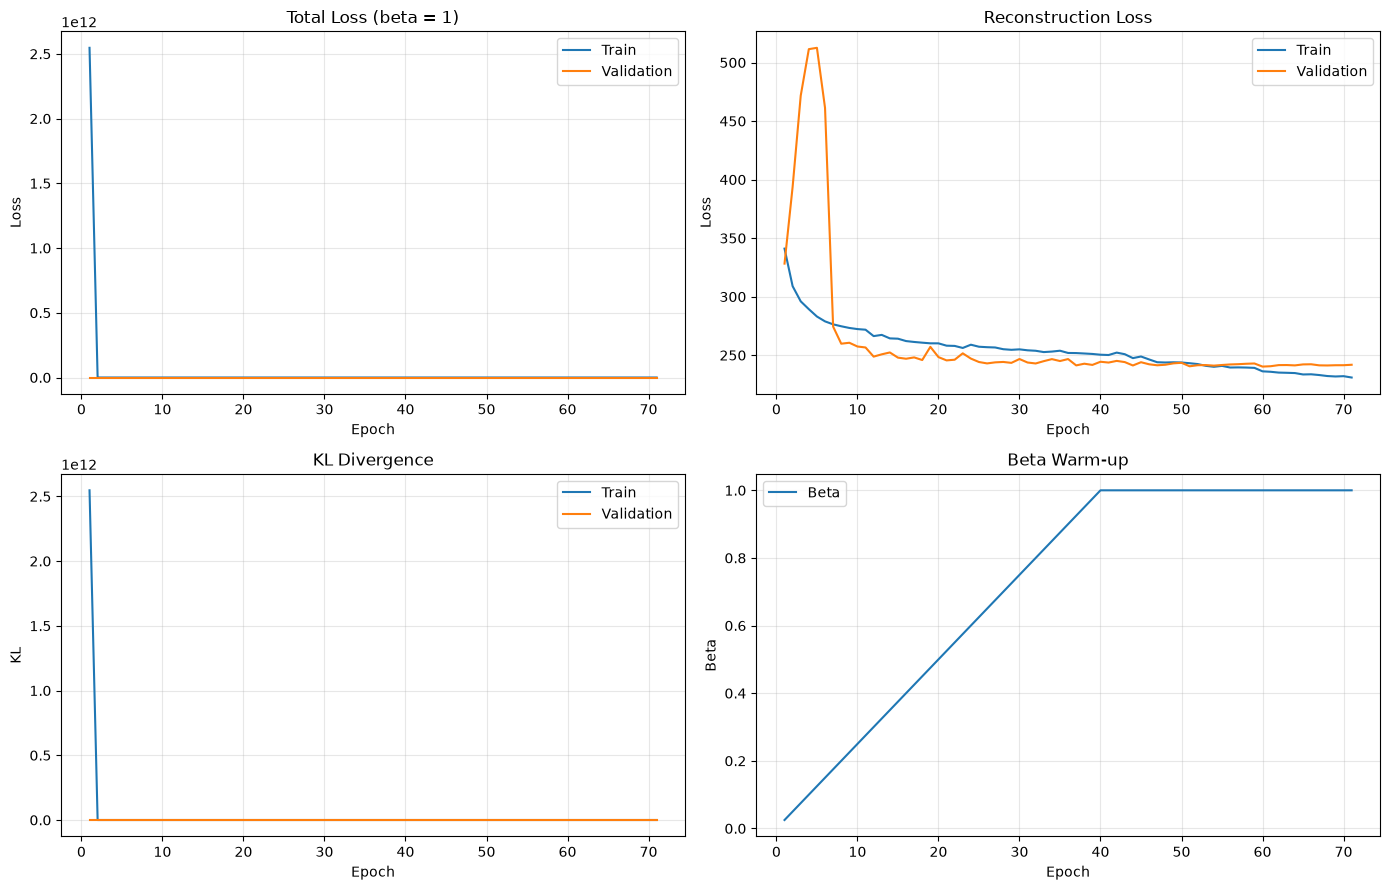

In [112]:
history_df = pd.DataFrame(history)

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 9)
)

# Perda total
axes[0, 0].plot(
    history_df["epoch"],
    history_df["train_total"],
    label="Train"
)

axes[0, 0].plot(
    history_df["epoch"],
    history_df["val_total"],
    label="Validation"
)

axes[0, 0].set_title("Total Loss (beta = 1)")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Reconstrução
axes[0, 1].plot(
    history_df["epoch"],
    history_df["train_recon"],
    label="Train"
)

axes[0, 1].plot(
    history_df["epoch"],
    history_df["val_recon"],
    label="Validation"
)

axes[0, 1].set_title("Reconstruction Loss")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Loss")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# Divergência KL
axes[1, 0].plot(
    history_df["epoch"],
    history_df["train_kl"],
    label="Train"
)

axes[1, 0].plot(
    history_df["epoch"],
    history_df["val_kl"],
    label="Validation"
)

axes[1, 0].set_title("KL Divergence")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("KL")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# Beta
axes[1, 1].plot(
    history_df["epoch"],
    history_df["beta"],
    label="Beta"
)

axes[1, 1].set_title("Beta Warm-up")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Beta")
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [113]:
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Melhor modelo carregado!")
print("Época:", checkpoint["epoch"])
print("Validação:", checkpoint["best_val_loss"])

Melhor modelo carregado!
Época: 51
Validação: 252.03378524780274


In [114]:
test_metrics = evaluate(
    model,
    test_loader
)

print("Resultados no conjunto de teste:")
print(f"Total Loss: {test_metrics['total']:.4f}")
print(f"Recon Loss: {test_metrics['recon']:.4f}")
print(f"KL Loss:    {test_metrics['kl']:.4f}")

Resultados no conjunto de teste:
Total Loss: 246.7886
Recon Loss: 235.2782
KL Loss:    11.5104


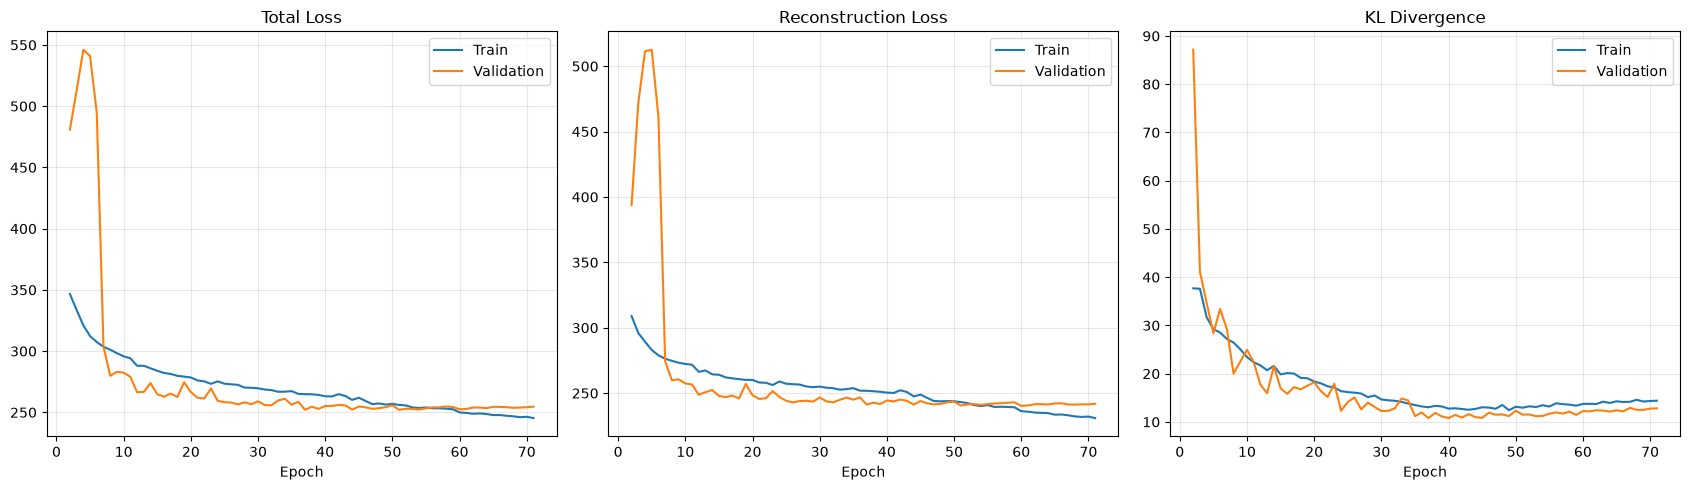

In [115]:
history_df = pd.DataFrame(history)

# Remover a primeira época apenas da visualização
# Os dados originais continuam preservados.
history_plot = history_df[
    history_df["epoch"] >= 2
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Loss total
axes[0].plot(
    history_plot["epoch"],
    history_plot["train_total"],
    label="Train"
)

axes[0].plot(
    history_plot["epoch"],
    history_plot["val_total"],
    label="Validation"
)

axes[0].set_title("Total Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Reconstruction
axes[1].plot(
    history_plot["epoch"],
    history_plot["train_recon"],
    label="Train"
)

axes[1].plot(
    history_plot["epoch"],
    history_plot["val_recon"],
    label="Validation"
)

axes[1].set_title("Reconstruction Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(alpha=0.3)

# KL
axes[2].plot(
    history_plot["epoch"],
    history_plot["train_kl"],
    label="Train"
)

axes[2].plot(
    history_plot["epoch"],
    history_plot["val_kl"],
    label="Validation"
)

axes[2].set_title("KL Divergence")
axes[2].set_xlabel("Epoch")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [116]:
def inspect_latent_space(model, loader, name):

    model.eval()

    all_mu = []
    all_logvar = []

    with torch.no_grad():

        for images, masks, conditions in loader:

            images = images.to(DEVICE)
            conditions = conditions.to(DEVICE)

            mu, logvar = model.encoder(
                images,
                conditions
            )

            all_mu.append(mu.cpu())
            all_logvar.append(logvar.cpu())

    mu = torch.cat(all_mu, dim=0)
    logvar = torch.cat(all_logvar, dim=0)

    std = torch.exp(0.5 * logvar)

    # KL por dimensão latente
    kl_per_dimension = -0.5 * (
        1 + logvar
        - mu.pow(2)
        - logvar.exp()
    ).mean(dim=0)

    print("=" * 55)
    print(name)

    print("\nMu:")
    print("Mean:", mu.mean().item())
    print("Std:", mu.std().item())
    print("Min:", mu.min().item())
    print("Max:", mu.max().item())

    print("\nLogvar:")
    print("Mean:", logvar.mean().item())
    print("Std:", logvar.std().item())
    print("Min:", logvar.min().item())
    print("Max:", logvar.max().item())

    print("\nDesvio padrão latente:")
    print("Mean:", std.mean().item())
    print("Min:", std.min().item())
    print("Max:", std.max().item())

    print("\nKL por dimensão:")
    print(kl_per_dimension.numpy())

    print(
        "\nDimensões com KL > 0.01:",
        (kl_per_dimension > 0.01).sum().item(),
        "/",
        LATENT_DIM
    )

    assert torch.isfinite(mu).all()
    assert torch.isfinite(logvar).all()
    assert torch.isfinite(std).all()

    return mu, logvar, kl_per_dimension

In [117]:
train_latent = inspect_latent_space(
    model,
    train_loader,
    "TRAIN"
)

val_latent = inspect_latent_space(
    model,
    val_loader,
    "VALIDATION"
)

TRAIN

Mu:
Mean: -0.008759099058806896
Std: 0.4881789982318878
Min: -4.649550914764404
Max: 4.654812812805176

Logvar:
Mean: -0.38249850273132324
Std: 0.7154890894889832
Min: -5.2042622566223145
Max: 0.417203813791275

Desvio padrão latente:
Mean: 0.865471363067627
Min: 0.07411546260118484
Max: 1.2319544553756714

KL por dimensão:
[0.07380591 0.39926398 0.11676896 0.02592085 1.1986617  0.02586965
 0.04234474 0.0376512  0.0265154  0.09759809 0.05193521 0.02246496
 0.04430672 0.04583926 0.027386   0.04234201 0.0477328  0.01838325
 2.118379   0.02410304 0.02371221 1.5447903  0.07675742 0.10636336
 0.3773173  0.0179635  0.04578864 0.07310116 0.02273873 0.04933564
 0.03186197 0.0298651  0.5679969  0.03159885 1.0256708  0.07710254
 0.02392433 0.04419333 0.00957561 0.03985194 0.05109531 0.02391626
 0.01928498 0.06784413 0.03431002 0.03393133 0.04674618 0.9080327
 0.03248277 0.0580053  0.03899068 0.15225181 0.01919035 0.03249384
 0.02463852 0.04265124 0.099309   0.03919827 0.0496731  0.8740641

In [118]:
def inspect_reconstruction_scale(dataset, num_samples=32):

    errors = []
    total_errors = []
    visible_pixels = []

    model.eval()

    with torch.no_grad():

        for i in range(min(num_samples, len(dataset))):

            image, mask, condition = dataset[i]

            image = image.unsqueeze(0).to(DEVICE)
            mask = mask.unsqueeze(0).to(DEVICE)
            condition = condition.unsqueeze(0).to(DEVICE)

            reconstruction = model.reconstruct(
                image,
                condition
            )

            error = torch.abs(
                image - reconstruction
            ) * mask

            error_sum = error.sum().item()
            pixel_count = mask.sum().item()

            total_errors.append(error_sum)
            visible_pixels.append(pixel_count)

            errors.append(
                error_sum / max(pixel_count, 1)
            )

    print("Erro absoluto total médio:", np.mean(total_errors))
    print("Pixels visíveis médios:", np.mean(visible_pixels))
    print("MAE médio por pixel visível:", np.mean(errors))

    return errors

In [119]:
test_pixel_errors = inspect_reconstruction_scale(
    test_dataset,
    num_samples=32
)

Erro absoluto total médio: 241.7636501789093
Pixels visíveis médios: 1314.125
MAE médio por pixel visível: 0.18521451970580433


In [120]:
def show_reconstructions(dataset, num_samples=8):

    model.eval()

    num_samples = min(
        num_samples,
        len(dataset)
    )

    fig, axes = plt.subplots(
        2,
        num_samples,
        figsize=(2.5 * num_samples, 5)
    )

    with torch.no_grad():

        for i in range(num_samples):

            image, mask, condition = dataset[i]

            image_input = image.unsqueeze(0).to(DEVICE)
            condition_input = condition.unsqueeze(0).to(DEVICE)

            reconstruction = model.reconstruct(
                image_input,
                condition_input
            )

            original = image.squeeze(0).numpy()
            mask_np = mask.squeeze(0).numpy()

            reconstructed = (
                reconstruction.squeeze(0).squeeze(0).cpu().numpy()
            )

            # Aplicar máscara somente na visualização
            reconstructed_display = reconstructed * mask_np

            row = dataset.df.iloc[i]

            types = [
                POKEMON_TYPES[j]
                for j in range(NUM_TYPES)
                if condition[j].item() == 1
            ]

            mae = (
                np.abs(original - reconstructed_display)
                * mask_np
            ).sum() / max(mask_np.sum(), 1)

            axes[0, i].imshow(
                original,
                cmap="gray",
                vmin=0,
                vmax=1
            )

            axes[0, i].set_title(
                f"{row['pokemon_name']}\nReal"
            )

            axes[1, i].imshow(
                reconstructed_display,
                cmap="gray",
                vmin=0,
                vmax=1
            )

            axes[1, i].set_title(
                f"Reconstrução\nMAE: {mae:.3f}"
            )

            axes[0, i].axis("off")
            axes[1, i].axis("off")

    plt.tight_layout()
    plt.show()

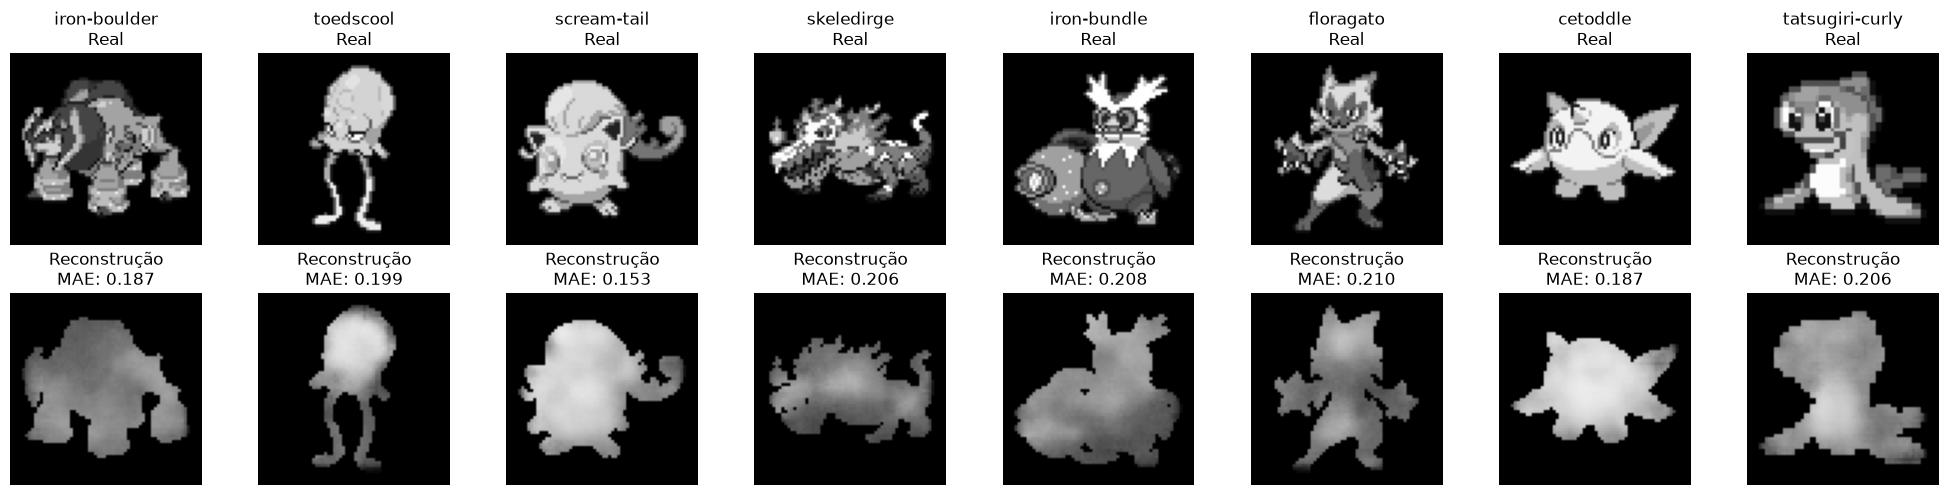

In [121]:
show_reconstructions(
    test_dataset,
    num_samples=8
)